# 01 · Data understanding

**Owner:** Charlotte

In [9]:
import sys
import os

sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

from src.data import load_raw, check_quality, make_split, load_train

FIG_PATH = os.path.join("..", "results", "figures", "eda")
os.makedirs(FIG_PATH, exist_ok=True)

In [2]:
df = load_raw()
issues = check_quality(df)

print("\n--- Blood Pressure Issues ---")
print(issues["bp_issues"][["SystolicBP", "DiastolicBP"]].head())

print("\n--- Cholesterol Issues ---")
print(issues["chol_issues"][["CholesterolTotal", "CholesterolLDL", "CholesterolHDL"]].head())


--- SHAPE ---
(2105, 33)

--- MISSING VALUES ---
No missing values

--- DUPLICATE ROWS ---
0 duplicate rows found

--- CLASS BALANCE ---
Diagnosis
1    1304
0     801
Name: count, dtype: int64
Diagnosis
1    0.619
0    0.381
Name: proportion, dtype: float64

--- INCONSISTENCY: DiastolicBP >= SystolicBP ---
200 observations flagged

--- INCONSISTENCY: LDL + HDL > CholesterolTotal ---
582 observations flagged

--- DTYPES ---
Age                           int64
Gender                        int64
Ethnicity                     int64
EducationLevel                int64
BMI                         float64
Smoking                       int64
AlcoholConsumption          float64
PhysicalActivity            float64
DietQuality                 float64
SleepQuality                float64
FamilyHistoryParkinsons       int64
TraumaticBrainInjury          int64
Hypertension                  int64
Diabetes                      int64
Depression                    int64
Stroke                        in

**Shape & Completeness**\
The dataset contains no missing values and no duplicate rows, so no imputation or deduplication is required.

**Class Balance**\
The dataset shows a moderate class imbalance: 61.9% of patients are diagnosed with Parkinson's Disease (PD) and 38.1% are not. This imbalance justifies the use of **F2-score** as the primary evaluation metric, as it prioritises recall — minimising false negatives is more critical in a medical screening context.

**Medical Inconsistencies**\
Two types of medically impossible value combinations were identified:
* Blood pressure: 5 observations have a DiastolicBP ≥ SystolicBP, which is physiologically impossible (diastolic pressure must always be lower than systolic pressure).
* Cholesterol: 5 observations have CholesterolLDL + CholesterolHDL > CholesterolTotal, which is impossible as LDL and HDL are components of total cholesterol. Note that one patient (PatientID: 3074) is affected by **both** issues.

Although each individual value falls within its documented range:
* Systolic BP: [90–180 mmHg], Diastolic BP: [60–120 mmHg]
* Total cholesterol: [150–300 mg/dL], LDL: [50–200 mg/dL], HDL: [20–100 mg/dL]

their **combinations** are medically unrealistic. As instructed, all observations are retained throughout the pipeline. This is acknowledged as a **known limitation of the synthetic dataset.**

In [3]:
make_split(df) # creates split.csv — run ONCE!

Split already exists at c:\Users\Charlotte\OneDrive\JADS\Semester 1\Advanced ML\Group\Assignment 2\VSCode\Parkinson-Disease-Classification\data\processed\split.csv. Skipping to prevent overwrite!


In [4]:
X_train, y_train = load_train()
df_train = X_train.copy()
df_train["Diagnosis"] = y_train

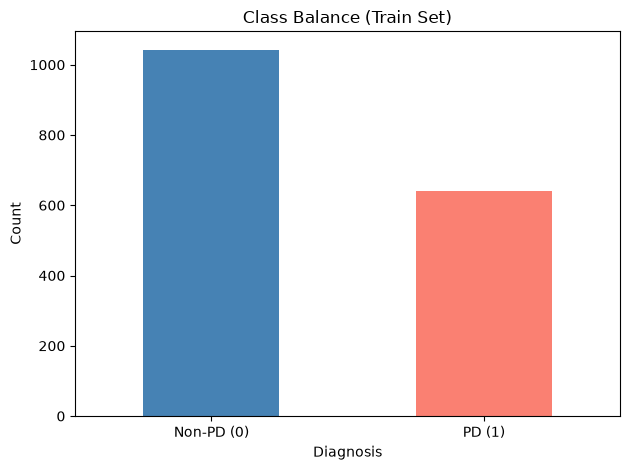

In [5]:
ax = y_train.value_counts().plot(kind="bar", color=["steelblue", "salmon"])
ax.set_xticklabels(["Non-PD (0)", "PD (1)"], rotation=0)
ax.set_title("Class Balance (Train Set)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "class_balance.png"), dpi=150)
plt.show()

Visualization of the class imbalance like mentioned before this imbalance justifies the use of **F2-score** as the primary evaluation metric.

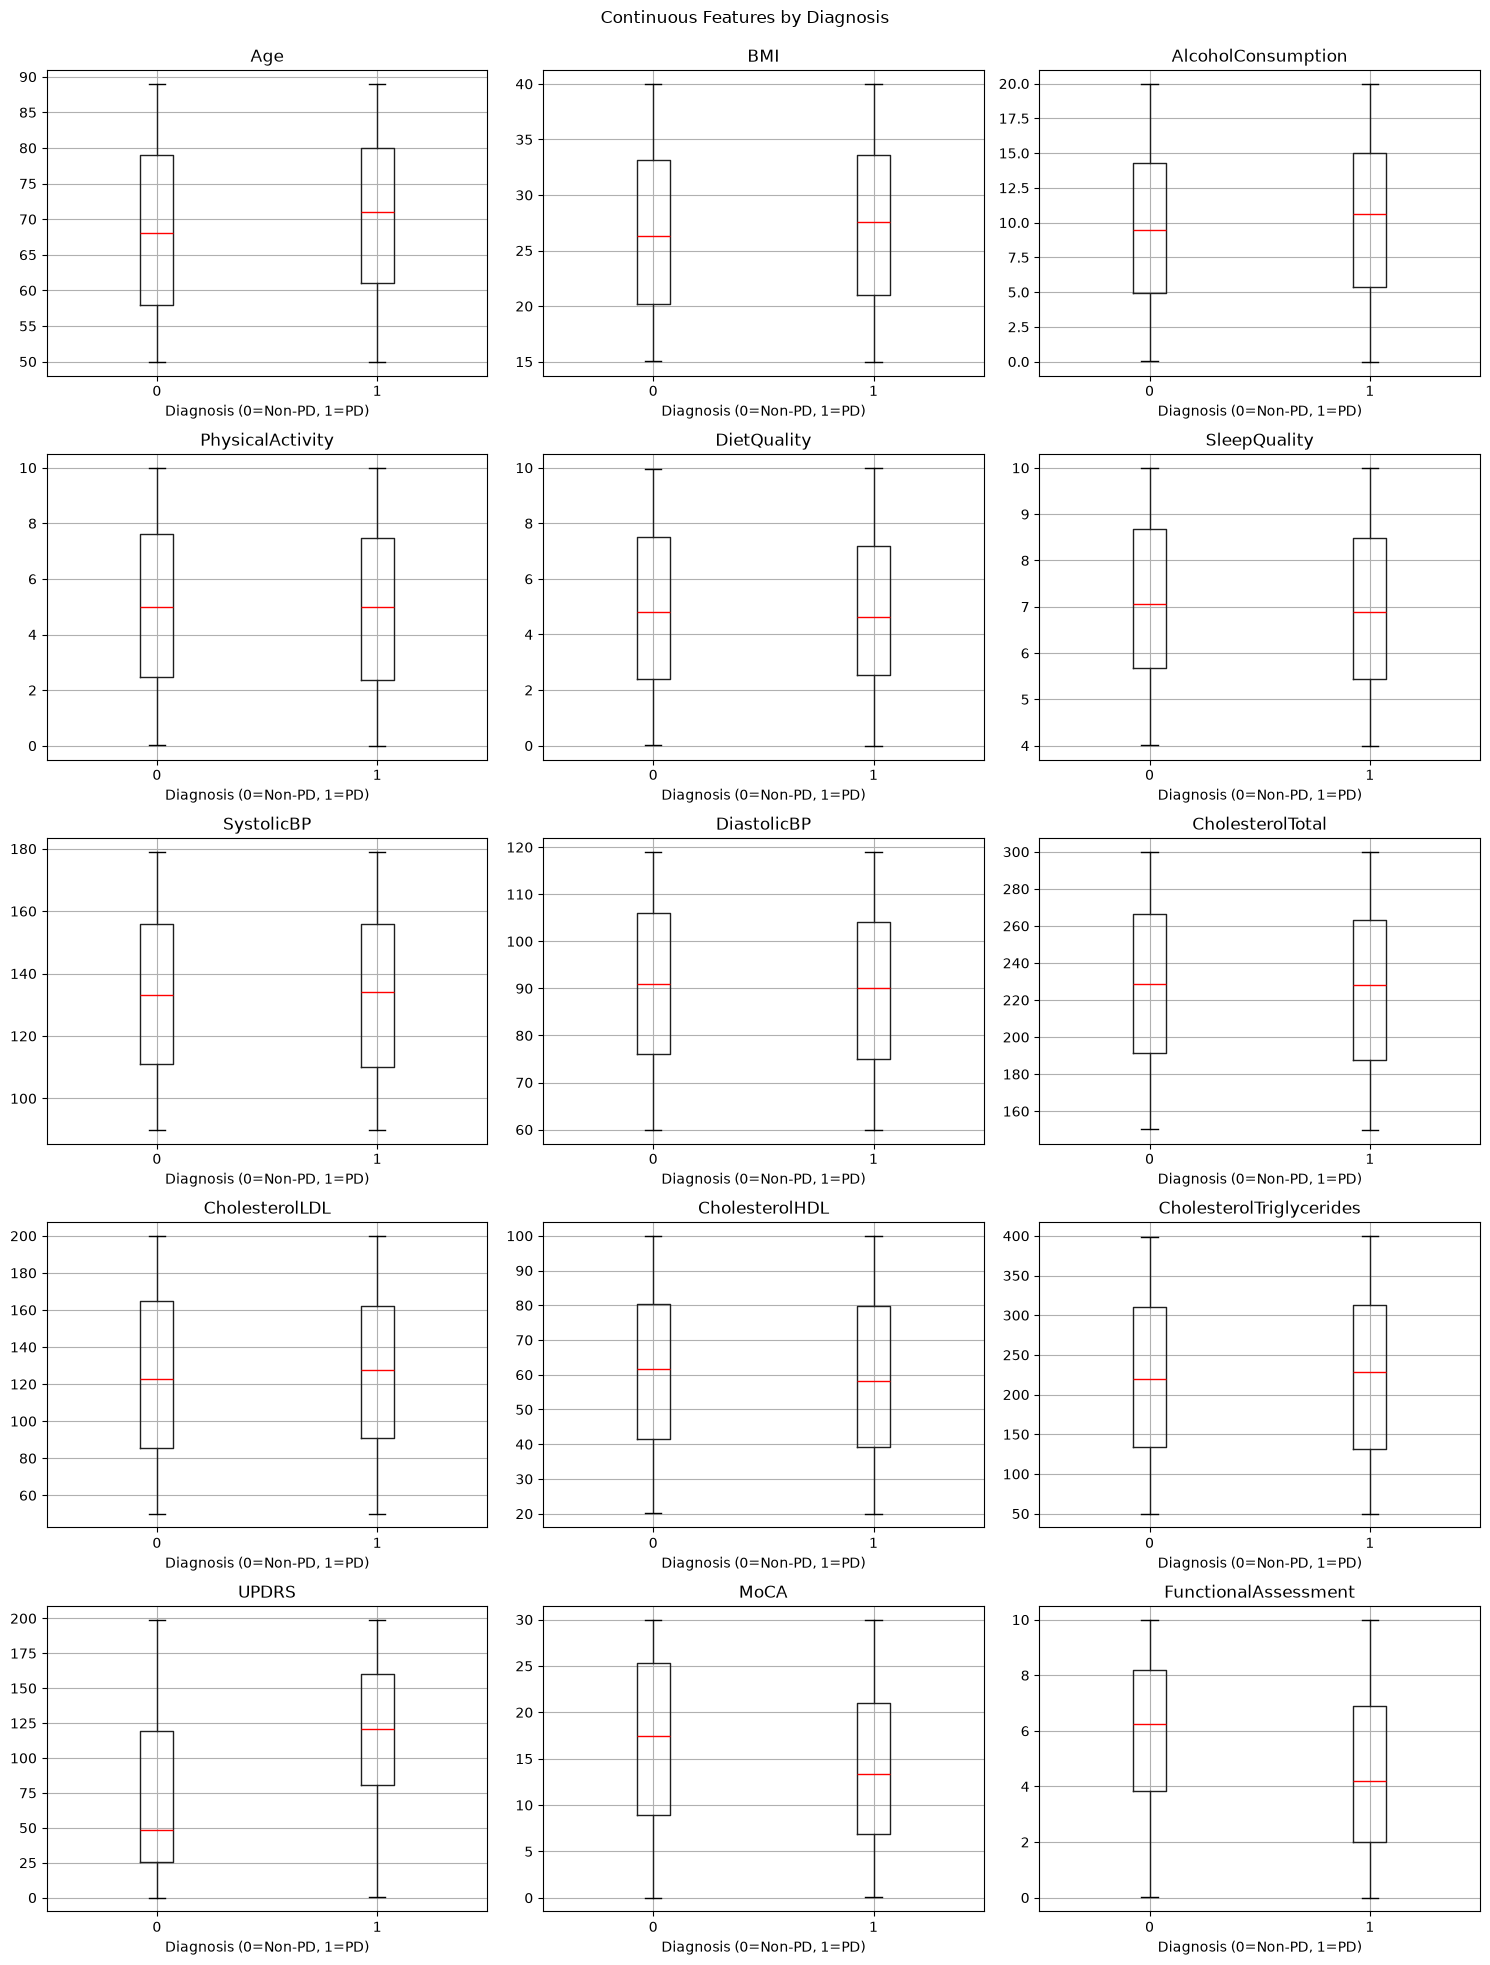

In [6]:
from src.data import CONTINUOUS_COLS

fig, axes = plt.subplots(5, 3, figsize=(15, 20))
axes = axes.flatten()

for i, col in enumerate(CONTINUOUS_COLS):
    df_train.boxplot(column=col, by="Diagnosis", ax=axes[i], medianprops={"color": "red"})
    axes[i].set_title(col)
    axes[i].set_xlabel("Diagnosis (0=Non-PD, 1=PD)")

plt.suptitle("Continuous Features by Diagnosis")
plt.tight_layout()
plt.subplots_adjust(top=0.95) 
plt.savefig(os.path.join(FIG_PATH, "continuous_by_diagnosis.png"), dpi=150)
plt.show()

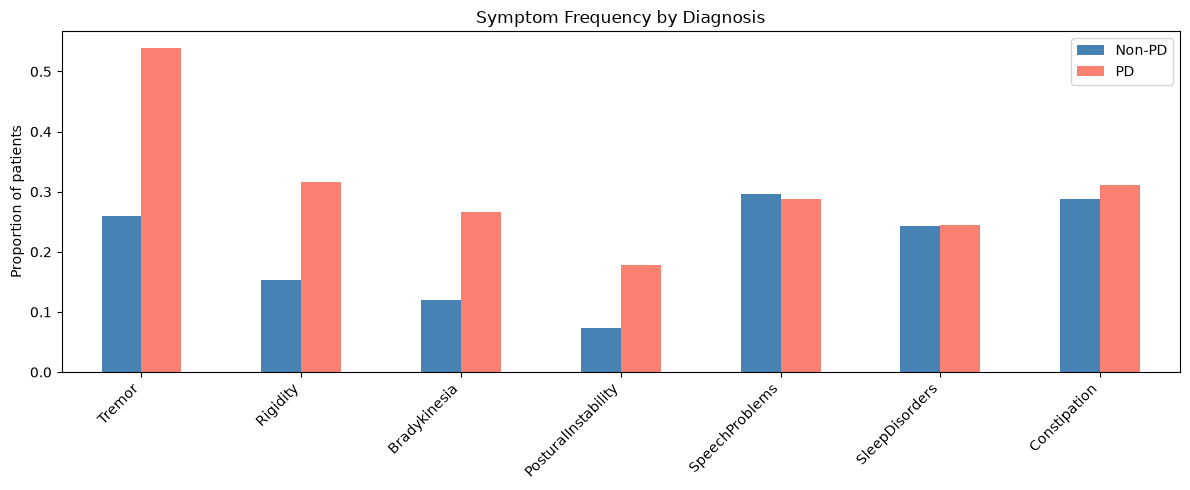

In [7]:
SYMPTOM_COLS = [
    "Tremor", "Rigidity", "Bradykinesia",
    "PosturalInstability", "SpeechProblems",
    "SleepDisorders", "Constipation"
]

symptom_rates = df_train.groupby("Diagnosis")[SYMPTOM_COLS].mean()
# print(symptom_rates)

symptom_rates.T.plot(kind="bar", figsize=(12, 5), color=["steelblue", "salmon"])
plt.title("Symptom Frequency by Diagnosis")
plt.ylabel("Proportion of patients")
plt.xticks(rotation=45, ha="right")
plt.legend(["Non-PD", "PD"])
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "symptom_frequency.png"), dpi=150)
plt.show()

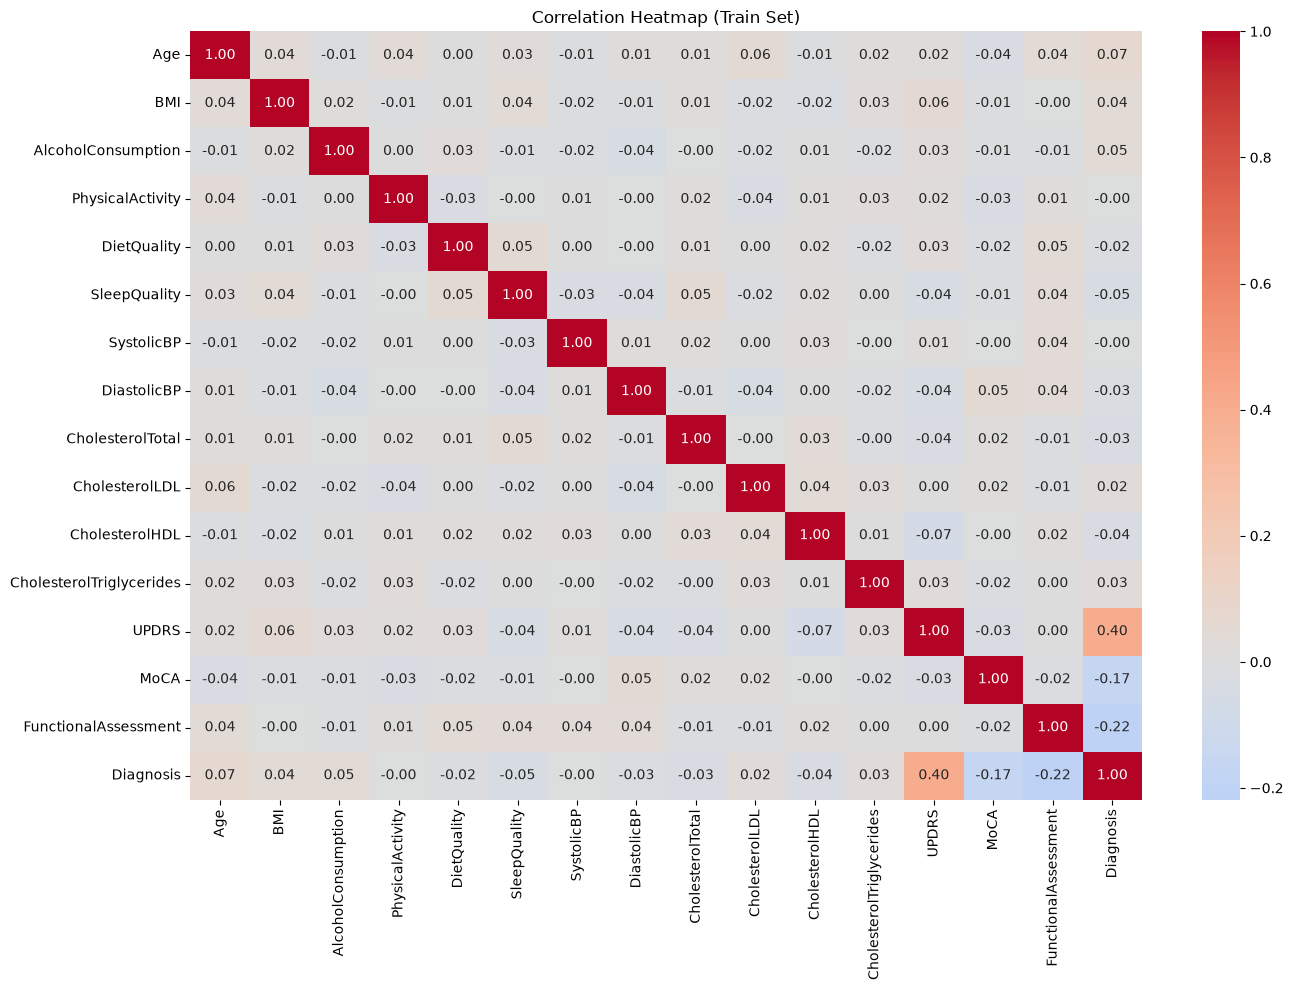

In [8]:
corr = df_train[CONTINUOUS_COLS + ["Diagnosis"]].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Train Set)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, "correlation_heatmap.png"), dpi=150)
plt.show()

In [10]:
print("=== Outlier Check (Z-score > 3) ===")
z_scores = np.abs(stats.zscore(df_train[CONTINUOUS_COLS]))
outlier_counts = (z_scores > 3).sum(axis=0) # empirical rule of normal distributions
print(outlier_counts[outlier_counts > 0])

=== Outlier Check (Z-score > 3) ===
[]


**Outlier Inspection**\
Z-score analysis (threshold > 3) identified no outliers across any of the
15 continuous features. This is expected given the synthetic nature of the
dataset — all features were generated within fixed documented ranges, making
extreme values unlikely by design. No observations are removed on the basis
of outliers.

#
# EDA Findings Summary

#
## Features That Best Separate PD from Non-PD

**Continuous features (correlation + box plot evidence):**
- **UPDRS** (r = +0.40): The strongest linear predictor of Diagnosis across
  all features. Box plots confirm clearly higher values in PD patients,
  consistent with UPDRS being a clinical scale specifically designed to
  measure Parkinson's severity.
- **FunctionalAssessment** (r = −0.22): Clearly lower scores in PD patients,
  reflecting the progressive motor impairment characteristic of
  Parkinson's Disease.
- **MoCA** (r = −0.17): Clearly lower cognitive scores in PD patients,
  reflecting the cognitive decline often observed in Parkinson's Disease.
- **Age**: Slightly higher in PD patients, consistent with age being a
  well-documented risk factor for Parkinson's Disease.

**Symptom flags (frequency by diagnosis):**
- **Tremor, Rigidity, Bradykinesia and PosturalInstability** show notably
  higher prevalence in PD patients. These are the four cardinal motor
  symptoms of Parkinson's Disease and their elevated frequency in PD
  patients is clinically expected.

**Note on correlation magnitudes:** All correlations are modest (≤ 0.40),
which is expected given the synthetic nature of the dataset. UPDRS has
the strongest linear relationship with Diagnosis of all features and
is the most informative single predictor.

#
## Anomalies & Limitations
- 5 observations have DiastolicBP ≥ SystolicBP (kept as instructed)
- 5 observations have CholesterolLDL + CholesterolHDL > CholesterolTotal
  (kept as instructed); PatientID 3074 is affected by both issues.
- No missing values, no duplicate rows and no outliers (Z-score > 3)
  detected across any feature.
- Class imbalance: 61.9% PD vs 38.1% Non-PD → justifies the use of
  **F2-score** as the primary evaluation metric, prioritising recall
  over precision in this medical screening context.

#
## Suggested FIS Inputs
Based on EDA findings, suggested primary inputs for the Fuzzy Inference
System are:

| Feature | Type | Justification |
|---|---|---|
| UPDRS | Continuous | Strongest predictor (r = +0.40), clearly higher in PD |
| MoCA | Continuous | Clearly lower in PD, reflects cognitive decline |
| FunctionalAssessment | Continuous | Clearly lower in PD, reflects motor impairment |
| Age | Continuous | Slightly higher in PD, well-known risk factor |
| SleepQuality | Continuous | Included as supporting continuous variable |
| PosturalInstability | Binary | Cardinal PD symptom, high prevalence in PD patients; note binary nature makes it less ideal as a fuzzy input but can serve as a supporting rule condition |
